# ATP Tennis - How long will it take?

Background: https://www.kaggle.com/datasets/guillemservera/tennis

***Question***  
Can we predict how long an ATP Tennis match is going to take?  



## Read data

In [1]:
import pandas as pd
import numpy as np

In [2]:
tennis_df = pd.read_csv("ATP_tennis_group_project.csv")
tennis_df = tennis_df.drop(columns=["Unnamed: 0"])

/var/folders/vr/sgzn8sxn267_nvqky6py1tr00000gn/T/ipykernel_54921/3161917845.py:1: DtypeWarning: Columns (9,17) have mixed types. Specify dtype option on import or set low_memory=False.
  tennis_df = pd.read_csv("ATP_tennis_group_project.csv")


In [3]:
pd.set_option('display.max_columns', None)
tennis_df.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points,year,has_stats
0,2000-301,Auckland,Hard,32,A,2000-01-10,1,103163,1.0,NaN,Tommy Haas,R,188.0,GER,21.7,101543,NaN,NaN,Jeff Tarango,L,180.0,USA,31.1,7-5 4-6 7-5,3,R32,108.0,18.0,4.0,96.0,49.0,39.0,28.0,17.0,3.0,5.0,7.0,8.0,106.0,55.0,39.0,29.0,17.0,4.0,7.0,11.0,1612.0,63.0,595.0,2000,True
1,2000-301,Auckland,Hard,32,A,2000-01-10,2,102607,NaN,Q,Juan Balcells,R,190.0,ESP,24.5,102644,NaN,NaN,Franco Squillari,L,183.0,ARG,24.3,7-5 7-5,3,R32,85.0,5.0,3.0,76.0,52.0,39.0,13.0,12.0,5.0,6.0,5.0,10.0,74.0,32.0,25.0,18.0,12.0,3.0,6.0,211.0,157.0,49.0,723.0,2000,True
2,2000-301,Auckland,Hard,32,A,2000-01-10,3,103252,NaN,NaN,Alberto Martin,R,175.0,ESP,21.3,102238,NaN,NaN,Alberto Berasategui,R,173.0,ESP,26.5,6-3 6-1,3,R32,56.0,0.0,0.0,55.0,35.0,25.0,12.0,8.0,1.0,1.0,0.0,6.0,56.0,33.0,20.0,7.0,8.0,7.0,11.0,48.0,726.0,59.0,649.0,2000,True
3,2000-301,Auckland,Hard,32,A,2000-01-10,4,103507,7.0,NaN,Juan Carlos Ferrero,R,183.0,ESP,19.9,103819,NaN,NaN,Roger Federer,R,185.0,SUI,18.4,6-4 6-4,3,R32,68.0,5.0,1.0,53.0,28.0,26.0,15.0,10.0,0.0,0.0,11.0,2.0,70.0,43.0,29.0,14.0,10.0,6.0,8.0,45.0,768.0,61.0,616.0,2000,True
4,2000-301,Auckland,Hard,32,A,2000-01-10,5,102103,NaN,Q,Michael Sell,R,180.0,USA,27.3,102765,4.0,NaN,Nicolas Escude,R,185.0,FRA,23.7,0-6 7-6(7) 6-1,3,R32,115.0,1.0,2.0,98.0,66.0,39.0,14.0,13.0,6.0,11.0,8.0,8.0,92.0,46.0,34.0,18.0,12.0,5.0,9.0,167.0,219.0,34.0,873.0,2000,True


In [4]:
tennis_df.shape

(66405, 51)

## Data Cleaning

***tourney_id*** --> keep, indicates specifics about a day  
***tourney_name*** --> keep  
***surface*** --> keep  
***draw_size***: Number of players in the draw; all participants in the tournament  
***tourney_level*** --> keep  
***tourney_date***: Maybe split by season? Or month or something  
***winner_id***: drop, we can use name instead  
***winner_seed*** indicates world ranking (if empty, ranking not high) --> is this before or after match?  
***winner_entry*** how did the player get into the tournament? Qulaification tournament, Wildcard, etc. --> What means empty?  
***winner_name***: Keep but correct for Edouard Roger Vasselin/Edouard Roger-Vasselin  
**winner_hand** --> keep  
**winner_ht**: size of the winner, keep  
***winner_ioc***: country of origin  
***winner_age***: --> keep  
***loser_id***: drop, we can use name instead  
***loser_seed***: indicates world ranking (if empty, ranking not high) --> is this before or after match?    
***loser_entry***: how did the player get into the tournament? Qulaification tournament, Wildcard, etc. --> What means empty?  
***loser_name***: Keep but correct for Edouard Roger Vasselin/Edouard Roger-Vasselin   
***loser_hand***: --> keep   
***loser_ht***: size of the loser, keep    
***loser_ioc***: country of origin  
***loser_age***: --> keep  
***score*** --> drop, we don't know before  
***best_of***: how many Sets CAN there be? --> keep  
***round***: Level in the tournament: Final/Semifinal/Quarterfinal/R R depends on the size of the tournament  
***minutes: dependend variable!*** 
***w_ace 	w_df 	w_svpt 	w_1stIn 	w_1stWon 	w_2ndWon 	w_SvGms 	w_bpSaved 	w_bpFaced 	l_ace 	l_df 	l_svpt 	l_1stIn l_1stWon 	l_2ndWon 	l_SvGms 	l_bpSaved 	l_bpFaced*** --> drop as they are statistics only known after the tournament  
***winner_rank***: interesting, but is it rank before or after? Also watch out counfundation with winner_seed     
***winner_rank_points***: interesting, but is it rank before or after?  
***loser_rank***: interesting, but is it rank before or after? Also watch out counfundation with loser_seed   
***loser_rank_points*** interesting, but is it rank before or after?    
***year*** --> keep  
***has_stats*** --> drop  

loser and winner must somehow be randomized per Tournament - we cannot keep information who won or who played against whom but it's important who was in the tournament

***keep***   
tourney_id  
tourney_name  
surface  
draw_size  
tourney_level  
winner_name: Keep but correct for Edouard Roger Vasselin/Edouard Roger-Vasselin  
winner_hand  
winner_ht  
winner_ioc  
winner_age  
loser_name: Keep but correct for Edouard Roger Vasselin/Edouard Roger-Vasselin  
loser_hand  
loser_ht 
loser_ioc  
loser_age  
best_of  
round  
year  
tourney_date  
winner_rank  
winner_rank_points  
loser_rank  
loser_rank_points  
   
*minutes*: dependend variable  


***drop***  
winner_id, loser_id --> duplicate of name  
score, w_ace w_df w_svpt w_1stIn w_1stWon w_2ndWon w_SvGms w_bpSaved w_bpFaced l_ace l_df l_svpt l_1stIn l_1stWon l_2ndWon l_SvGms l_bpSaved l_bpFaced --> data leakage
winner_seed/loser_seed
winner_entry
loser_entry:


***discussion***  
participants: all participant data is labeled as winner/loser --> data leakage.  
*Solution*: Randomize winner and loser to player_1 and player_2 (and so all connected data)

In [6]:
tennis_df.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points,year,has_stats
0,2000-301,Auckland,Hard,32,A,2000-01-10,1,103163,1.0,NaN,Tommy Haas,R,188.0,GER,21.7,101543,NaN,NaN,Jeff Tarango,L,180.0,USA,31.1,7-5 4-6 7-5,3,R32,108.0,18.0,4.0,96.0,49.0,39.0,28.0,17.0,3.0,5.0,7.0,8.0,106.0,55.0,39.0,29.0,17.0,4.0,7.0,11.0,1612.0,63.0,595.0,2000,True
1,2000-301,Auckland,Hard,32,A,2000-01-10,2,102607,NaN,Q,Juan Balcells,R,190.0,ESP,24.5,102644,NaN,NaN,Franco Squillari,L,183.0,ARG,24.3,7-5 7-5,3,R32,85.0,5.0,3.0,76.0,52.0,39.0,13.0,12.0,5.0,6.0,5.0,10.0,74.0,32.0,25.0,18.0,12.0,3.0,6.0,211.0,157.0,49.0,723.0,2000,True
2,2000-301,Auckland,Hard,32,A,2000-01-10,3,103252,NaN,NaN,Alberto Martin,R,175.0,ESP,21.3,102238,NaN,NaN,Alberto Berasategui,R,173.0,ESP,26.5,6-3 6-1,3,R32,56.0,0.0,0.0,55.0,35.0,25.0,12.0,8.0,1.0,1.0,0.0,6.0,56.0,33.0,20.0,7.0,8.0,7.0,11.0,48.0,726.0,59.0,649.0,2000,True
3,2000-301,Auckland,Hard,32,A,2000-01-10,4,103507,7.0,NaN,Juan Carlos Ferrero,R,183.0,ESP,19.9,103819,NaN,NaN,Roger Federer,R,185.0,SUI,18.4,6-4 6-4,3,R32,68.0,5.0,1.0,53.0,28.0,26.0,15.0,10.0,0.0,0.0,11.0,2.0,70.0,43.0,29.0,14.0,10.0,6.0,8.0,45.0,768.0,61.0,616.0,2000,True
4,2000-301,Auckland,Hard,32,A,2000-01-10,5,102103,NaN,Q,Michael Sell,R,180.0,USA,27.3,102765,4.0,NaN,Nicolas Escude,R,185.0,FRA,23.7,0-6 7-6(7) 6-1,3,R32,115.0,1.0,2.0,98.0,66.0,39.0,14.0,13.0,6.0,11.0,8.0,8.0,92.0,46.0,34.0,18.0,12.0,5.0,9.0,167.0,219.0,34.0,873.0,2000,True


### drop columns

In [10]:
tennis_df = pd.read_csv("ATP_tennis_group_project.csv")

cols_to_drop = [
    "Unnamed: 0", "winner_id", "loser_id",
    "score",
    "w_ace", "w_df", "w_svpt", "w_1stIn", "w_1stWon", "w_2ndWon", "w_SvGms", "w_bpSaved", 
    "w_bpFaced",
    "l_ace", "l_df", "l_svpt", "l_1stIn", "l_1stWon", "l_2ndWon", "l_SvGms", "l_bpSaved", 
    "l_bpFaced",
    "winner_seed", "loser_seed",
    "winner_entry", "loser_entry", "has_stats", "match_num"
]

tennis_df = tennis_df.drop(columns=cols_to_drop)

tennis_df.head()

/var/folders/vr/sgzn8sxn267_nvqky6py1tr00000gn/T/ipykernel_54921/2726276359.py:1: DtypeWarning: Columns (9,17) have mixed types. Specify dtype option on import or set low_memory=False.
  tennis_df = pd.read_csv("ATP_tennis_group_project.csv")


,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,best_of,round,minutes,winner_rank,winner_rank_points,loser_rank,loser_rank_points,year
0,2000-301,Auckland,Hard,32,A,2000-01-10,Tommy Haas,R,188.0,GER,21.7,Jeff Tarango,L,180.0,USA,31.1,3,R32,108.0,11.0,1612.0,63.0,595.0,2000
1,2000-301,Auckland,Hard,32,A,2000-01-10,Juan Balcells,R,190.0,ESP,24.5,Franco Squillari,L,183.0,ARG,24.3,3,R32,85.0,211.0,157.0,49.0,723.0,2000
2,2000-301,Auckland,Hard,32,A,2000-01-10,Alberto Martin,R,175.0,ESP,21.3,Alberto Berasategui,R,173.0,ESP,26.5,3,R32,56.0,48.0,726.0,59.0,649.0,2000
3,2000-301,Auckland,Hard,32,A,2000-01-10,Juan Carlos Ferrero,R,183.0,ESP,19.9,Roger Federer,R,185.0,SUI,18.4,3,R32,68.0,45.0,768.0,61.0,616.0,2000
4,2000-301,Auckland,Hard,32,A,2000-01-10,Michael Sell,R,180.0,USA,27.3,Nicolas Escude,R,185.0,FRA,23.7,3,R32,115.0,167.0,219.0,34.0,873.0,2000


### extract month from tourney date

In [11]:
tennis_df["month"] = pd.to_datetime(tennis_df["tourney_date"]).dt.month
tennis_df["tourney_month_sin"] = np.sin(2 * np.pi * tennis_df["month"] / 12)
tennis_df["tourney_month_cos"] = np.cos(2 * np.pi * tennis_df["month"] / 12)
tennis_df = tennis_df.drop(columns=["tourney_date", "month"])
tennis_df.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,best_of,round,minutes,winner_rank,winner_rank_points,loser_rank,loser_rank_points,year,tourney_month_sin,tourney_month_cos
0,2000-301,Auckland,Hard,32,A,Tommy Haas,R,188.0,GER,21.7,Jeff Tarango,L,180.0,USA,31.1,3,R32,108.0,11.0,1612.0,63.0,595.0,2000,0.5,0.866025
1,2000-301,Auckland,Hard,32,A,Juan Balcells,R,190.0,ESP,24.5,Franco Squillari,L,183.0,ARG,24.3,3,R32,85.0,211.0,157.0,49.0,723.0,2000,0.5,0.866025
2,2000-301,Auckland,Hard,32,A,Alberto Martin,R,175.0,ESP,21.3,Alberto Berasategui,R,173.0,ESP,26.5,3,R32,56.0,48.0,726.0,59.0,649.0,2000,0.5,0.866025
3,2000-301,Auckland,Hard,32,A,Juan Carlos Ferrero,R,183.0,ESP,19.9,Roger Federer,R,185.0,SUI,18.4,3,R32,68.0,45.0,768.0,61.0,616.0,2000,0.5,0.866025
4,2000-301,Auckland,Hard,32,A,Michael Sell,R,180.0,USA,27.3,Nicolas Escude,R,185.0,FRA,23.7,3,R32,115.0,167.0,219.0,34.0,873.0,2000,0.5,0.866025


### fix name duplicate

In [12]:
tennis_df = tennis_df.replace("Edouard Roger-Vasselin", "Edouard Roger Vasselin")

### blind the information of winning or losing

In [13]:
# random mask
mask = np.random.rand(len(tennis_df)) > 0.5

# all winner/loser column pairs
winner_cols = ['winner_name', 'winner_hand', 'winner_ht', 'winner_ioc', 'winner_age',
               'winner_rank', 'winner_rank_points']
loser_cols  = ['loser_name',  'loser_hand',  'loser_ht',  'loser_ioc',  'loser_age',
               'loser_rank',  'loser_rank_points']
new_cols_1  = ['name_1', 'hand_1', 'ht_1', 'ioc_1', 'age_1', 'rank_1', 'rank_points_1']
new_cols_2  = ['name_2', 'hand_2', 'ht_2', 'ioc_2', 'age_2', 'rank_2', 'rank_points_2']

for w, l, c1, c2 in zip(winner_cols, loser_cols, new_cols_1, new_cols_2):
    tennis_df[c1] = np.where(mask, tennis_df[w], tennis_df[l])
    tennis_df[c2] = np.where(mask, tennis_df[l], tennis_df[w])

# drop original columns
tennis_df.drop(columns=winner_cols + loser_cols, inplace=True)

long_df = tennis_df.copy()

In [14]:
long_df.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,best_of,round,minutes,year,tourney_month_sin,tourney_month_cos,name_1,name_2,hand_1,hand_2,ht_1,ht_2,ioc_1,ioc_2,age_1,age_2,rank_1,rank_2,rank_points_1,rank_points_2
0,2000-301,Auckland,Hard,32,A,3,R32,108.0,2000,0.5,0.866025,Tommy Haas,Jeff Tarango,R,L,188.0,180.0,GER,USA,21.7,31.1,11.0,63.0,1612.0,595.0
1,2000-301,Auckland,Hard,32,A,3,R32,85.0,2000,0.5,0.866025,Juan Balcells,Franco Squillari,R,L,190.0,183.0,ESP,ARG,24.5,24.3,211.0,49.0,157.0,723.0
2,2000-301,Auckland,Hard,32,A,3,R32,56.0,2000,0.5,0.866025,Alberto Martin,Alberto Berasategui,R,R,175.0,173.0,ESP,ESP,21.3,26.5,48.0,59.0,726.0,649.0
3,2000-301,Auckland,Hard,32,A,3,R32,68.0,2000,0.5,0.866025,Juan Carlos Ferrero,Roger Federer,R,R,183.0,185.0,ESP,SUI,19.9,18.4,45.0,61.0,768.0,616.0
4,2000-301,Auckland,Hard,32,A,3,R32,115.0,2000,0.5,0.866025,Michael Sell,Nicolas Escude,R,R,180.0,185.0,USA,FRA,27.3,23.7,167.0,34.0,219.0,873.0


### remove duplicates

In [15]:
long_df = long_df.drop_duplicates()

### deal with missing data

In [16]:
long_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66405 entries, 0 to 66404
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   tourney_id         66405 non-null  object 
 1   tourney_name       66405 non-null  object 
 2   surface            66405 non-null  object 
 3   draw_size          66405 non-null  int64  
 4   tourney_level      66405 non-null  object 
 5   best_of            66405 non-null  int64  
 6   round              66405 non-null  object 
 7   minutes            64152 non-null  float64
 8   year               66405 non-null  int64  
 9   tourney_month_sin  66405 non-null  float64
 10  tourney_month_cos  66405 non-null  float64
 11  name_1             66405 non-null  object 
 12  name_2             66405 non-null  object 
 13  hand_1             66405 non-null  object 
 14  hand_2             66405 non-null  object 
 15  ht_1               65741 non-null  float64
 16  ht_2               657

In [17]:
#delete rows without minutes
long_df = long_df.dropna(subset=["minutes"])
long_df = long_df[long_df["minutes"] > 0]

#fill empty rank/rankpoints with 9999 or 0
long_df["rank_1"] = long_df["rank_1"].fillna(9999)
long_df["rank_2"] = long_df["rank_2"].fillna(9999)
long_df["rank_points_1"] = long_df["rank_points_1"].fillna(0)
long_df["rank_points_2"] = long_df["rank_points_2"].fillna(0)

# impute age and ht with MICE
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

imputer = IterativeImputer(random_state=42)

long_df[["age_1", "ht_1", "age_2", "ht_2"]] = imputer.fit_transform(
    long_df[["age_1", "ht_1", "age_2", "ht_2"]]
)

long_df.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,best_of,round,minutes,year,tourney_month_sin,tourney_month_cos,name_1,name_2,hand_1,hand_2,ht_1,ht_2,ioc_1,ioc_2,age_1,age_2,rank_1,rank_2,rank_points_1,rank_points_2
0,2000-301,Auckland,Hard,32,A,3,R32,108.0,2000,0.5,0.866025,Tommy Haas,Jeff Tarango,R,L,188.0,180.0,GER,USA,21.7,31.1,11.0,63.0,1612.0,595.0
1,2000-301,Auckland,Hard,32,A,3,R32,85.0,2000,0.5,0.866025,Juan Balcells,Franco Squillari,R,L,190.0,183.0,ESP,ARG,24.5,24.3,211.0,49.0,157.0,723.0
2,2000-301,Auckland,Hard,32,A,3,R32,56.0,2000,0.5,0.866025,Alberto Martin,Alberto Berasategui,R,R,175.0,173.0,ESP,ESP,21.3,26.5,48.0,59.0,726.0,649.0
3,2000-301,Auckland,Hard,32,A,3,R32,68.0,2000,0.5,0.866025,Juan Carlos Ferrero,Roger Federer,R,R,183.0,185.0,ESP,SUI,19.9,18.4,45.0,61.0,768.0,616.0
4,2000-301,Auckland,Hard,32,A,3,R32,115.0,2000,0.5,0.866025,Michael Sell,Nicolas Escude,R,R,180.0,185.0,USA,FRA,27.3,23.7,167.0,34.0,219.0,873.0


### data types

In [19]:
#label encoding
from sklearn.preprocessing import LabelEncoder

cat_cols = ["tourney_id", "tourney_name", "name_1", "name_2", "ioc_1", "ioc_2"]

le = LabelEncoder()
for col in cat_cols:
    long_df[col] = le.fit_transform(long_df[col].astype(str))

#one hot encoding
long_df = pd.get_dummies(long_df, columns=["tourney_level", "surface", "hand_1", "hand_2"])
bool_cols = long_df.select_dtypes(include="bool").columns
long_df[bool_cols] = long_df[bool_cols].astype(int)

# ordinal encoding
round_order = {
    "R128": 1, "R64": 2, "R32": 3, "R16": 4,
    "QF": 5, "SF": 6, "F": 7,
    "RR": 3,
    "ER": 1,
    "BR": 6
}
long_df["round"] = long_df["round"].map(round_order)

In [20]:
long_df.head()

,tourney_id,tourney_name,draw_size,best_of,round,minutes,year,tourney_month_sin,tourney_month_cos,name_1,name_2,ht_1,ht_2,ioc_1,ioc_2,age_1,age_2,rank_1,rank_2,rank_points_1,rank_points_2,tourney_level_A,tourney_level_F,tourney_level_G,tourney_level_M,surface_Carpet,surface_Clay,surface_Grass,surface_Hard,hand_1_L,hand_1_R,hand_1_U,hand_2_A,hand_2_L,hand_2_R,hand_2_U
0,0,12,32,3,3,108.0,2000,0.5,0.866025,1263,600,188.0,180.0,32,79,21.7,31.1,11.0,63.0,1612.0,595.0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0
1,0,12,32,3,3,85.0,2000,0.5,0.866025,658,416,190.0,183.0,26,1,24.5,24.3,211.0,49.0,157.0,723.0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0
2,0,12,32,3,3,56.0,2000,0.5,0.866025,26,26,175.0,173.0,26,27,21.3,26.5,48.0,59.0,726.0,649.0,1,0,0,0,0,0,0,1,0,1,0,0,0,1,0
3,0,12,32,3,3,68.0,2000,0.5,0.866025,659,1123,183.0,185.0,26,68,19.9,18.4,45.0,61.0,768.0,616.0,1,0,0,0,0,0,0,1,0,1,0,0,0,1,0
4,0,12,32,3,3,115.0,2000,0.5,0.866025,901,965,180.0,185.0,79,30,27.3,23.7,167.0,34.0,219.0,873.0,1,0,0,0,0,0,0,1,0,1,0,0,0,1,0


## Train Test Split

In [21]:
from sklearn.model_selection import train_test_split
X = long_df.drop(columns=["minutes"])
y = long_df["minutes"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
X_train.to_csv("X_train")
X_test.to_csv("X_test")
y_train.to_csv("y_train")
y_test.to_csv("y_test")

In [23]:
y_train.describe()

count    51276.000000
mean       107.025529
std         41.224802
min          3.000000
25%         77.000000
50%         99.000000
75%        130.000000
max       1146.000000
Name: minutes, dtype: float64

In [24]:
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])
print(y_train.isnull().sum()[y_train.isnull().sum() > 0])
print(y_test.isnull().sum()[y_test.isnull().sum() > 0])

Series([], dtype: int64)
Series([], dtype: int64)
[]
[]


## Model 1  
basic: all variables, no feature engineering

In [25]:
#import h2o
#from h2o.automl import H2OAutoML

#h2o.init()

#train = h2o.H2OFrame(pd.concat([X_train, y_train], axis=1))
#test  = h2o.H2OFrame(pd.concat([X_test, y_test], axis=1))

#aml = H2OAutoML(max_runtime_secs=600, seed=42)
#aml.train(y="minutes", training_frame=train)

#print(aml.leaderboard)

## Model 2  
15 best variables, no feature engineering

In [26]:
#from sklearn.feature_selection import SelectKBest, f_regression

#selector = SelectKBest(f_regression, k=15)  # Top 15 Features
#X_train_selected = selector.fit_transform(X_train, y_train)

#selected_features = X_train.columns[selector.get_support()].tolist()
#print(selected_features)

In [27]:
#train_selected = h2o.H2OFrame(pd.concat([X_train[selected_features], y_train], axis=1))
#test_selected = h2o.H2OFrame(pd.concat([X_test[selected_features], y_test], axis=1))

#aml = H2OAutoML(max_runtime_secs=600, seed=42, sort_metric="RMSE")
#aml.train(y="minutes", training_frame=train_selected)

#print(aml.leaderboard)

## Model 3  
feature engineering: differences between players  
best 15 fatures

In [28]:
#from sklearn.feature_selection import SelectKBest, f_regression

#selector = SelectKBest(f_regression, k=15)  # Top 15 Features
#X_train_selected = selector.fit_transform(X_train, y_train)

##selected_features = X_train.columns[selector.get_support()].tolist()
#print(selected_features)

In [29]:
#train_selected = h2o.H2OFrame(pd.concat([X_train[selected_features], y_train], axis=1))
#test_selected = h2o.H2OFrame(pd.concat([X_test[selected_features], y_test], axis=1))

#aml = H2OAutoML(max_runtime_secs=600, seed=42, sort_metric="RMSE")
#aml.train(y="minutes", training_frame=train_selected)

#print(aml.leaderboard)

## Model 4 
feature engineering: none   
all fatures

In [30]:
import h2o
from h2o.automl import H2OAutoML

h2o.init()

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "25.0.4.1" 2026-08-18 LTS; OpenJDK Runtime Environment Temurin-25.0.4.1+1 (build 25.0.4.1+1-LTS); OpenJDK 64-Bit Server VM Temurin-25.0.4.1+1 (build 25.0.4.1+1-LTS, mixed mode)
  Starting server from /Users/piapeterschik/opt/anaconda3/envs/conda_environment/lib/python3.11/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /var/folders/vr/sgzn8sxn267_nvqky6py1tr00000gn/T/tmp79ov5z_h
  JVM stdout: /var/folders/vr/sgzn8sxn267_nvqky6py1tr00000gn/T/tmp79ov5z_h/h2o_piapeterschik_started_from_python.out
  JVM stderr: /var/folders/vr/sgzn8sxn267_nvqky6py1tr00000gn/T/tmp79ov5z_h/h2o_piapeterschik_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,05 secs
H2O_cluster_timezone:,Europe/Berlin
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,1 month and 24 days
H2O_cluster_name:,H2O_from_python_piapeterschik_manxxp
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,1.981 Gb
H2O_cluster_total_cores:,4
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


In [31]:
train = h2o.H2OFrame(pd.concat([X_train, y_train], axis=1))
test  = h2o.H2OFrame(pd.concat([X_test, y_test], axis=1))

aml = H2OAutoML(max_runtime_secs=600, seed=42)
aml.train(y="minutes", training_frame=train)

print(aml.leaderboard)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
model_id                                                    rmse      mse      mae     rmsle    mean_residual_deviance
StackedEnsemble_AllModels_3_AutoML_1_20261005_205401     34.9614  1222.3   27.5577  0.333764                   1222.3
StackedEnsemble_AllModels_2_AutoML_1_20261005_205401     34.9678  1222.74  27.5618  0.333833                   1222.74
StackedEnsemble_AllModels_1_AutoML_1_20261005_205401     34.9789  1223.52  27.5703  0.333946                   1223.52
StackedEnsemble_BestOfFamily_3_AutoML_1_20261005_205401  35.0002  1225.02  27.588   0.334088                   1225.02
StackedEnsemble_BestOfFamily_2_AutoML_1_20261005_205401  35.0229  1226.6   27.6117  0.334351                   1226.6
Sta

### First non-Ensemble Model

In [32]:
for model_id in aml.leaderboard['model_id'].as_data_frame()['model_id']:
    if 'Stacked' not in model_id:
        best_single = h2o.get_model(model_id)
        break

varimp = best_single.varimp(use_pandas=True)
print(varimp.head(20))

             variable  relative_importance  scaled_importance  percentage
0             best_of         8.962161e+07           1.000000    0.559535
1     tourney_level_G         1.475527e+07           0.164640    0.092122
2          tourney_id         6.816641e+06           0.076060    0.042558
3           draw_size         4.312486e+06           0.048119    0.026924
4       rank_points_2         3.471396e+06           0.038734    0.021673
5               round         3.443563e+06           0.038423    0.021499
6              name_1         3.290576e+06           0.036716    0.020544
7       rank_points_1         3.276765e+06           0.036562    0.020458
8               age_2         3.123742e+06           0.034855    0.019502
9               age_1         2.972601e+06           0.033168    0.018559
10             name_2         2.938659e+06           0.032790    0.018347
11               year         2.913122e+06           0.032505    0.018187
12               ht_1         2.638360

/Users/piapeterschik/opt/anaconda3/envs/conda_environment/lib/python3.11/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


### Plot important features

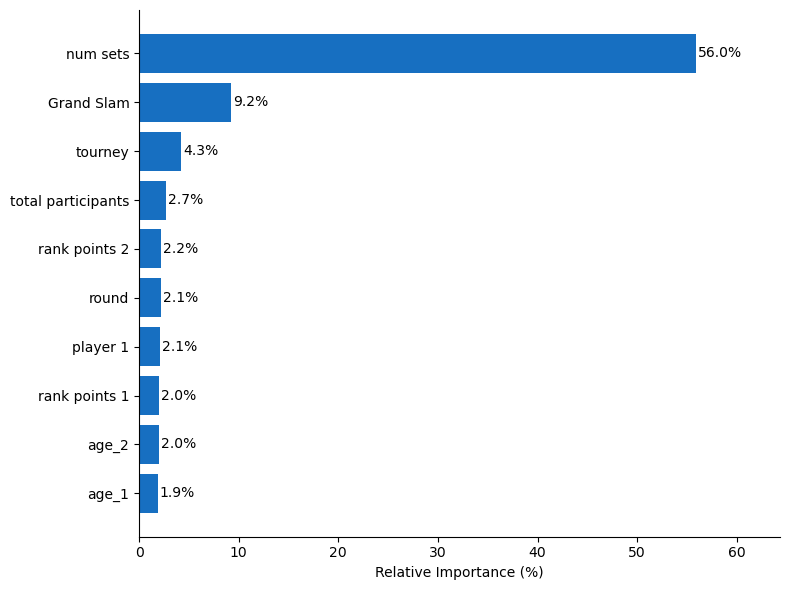

In [33]:
import matplotlib.pyplot as plt

# Top 10 Features
rename_map = {
    'best_of': 'num sets',
    'draw_size': 'total participants',
    'tourney_level_G': 'Grand Slam',
    'tourney_id': 'tourney',
    'year': 'year',
    'rank_points_1': 'rank points 1',
    'round': 'round',
    'rank_points_2': 'rank points 2',
    'name_1': 'player 1',
    'name_2': 'player 2'
}

top10 = varimp.head(10).sort_values('percentage', ascending=True)
top10 = top10.copy()
top10['variable'] = top10['variable'].map(rename_map).fillna(top10['variable'])

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(top10['variable'], top10['percentage'] * 100, color='steelblue')

for bar, val in zip(bars, top10['percentage'] * 100):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=10)

bars = ax.barh(top10['variable'], top10['percentage'] * 100, color='#176FC1')
ax.set_xlabel('Relative Importance (%)')
ax.set_xlim(0, top10['percentage'].max() * 100 * 1.15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('feature_importance_top10.png', dpi=150)
plt.show()

## Baseline Model

In [34]:
import numpy as np

# Durchschnittliche Matchdauer nach best_of
baseline = long_df.groupby('best_of')['minutes'].mean()
print(baseline)

# Vorhersage: einfach den Mittelwert pro Kategorie
def predict_duration(best_of):
    return baseline[best_of]

# RMSE auf Testset
y_pred = X_test['best_of'].map(baseline)
rmse_baseline = np.sqrt(((y_test - y_pred) ** 2).mean())
print(f"\nBaseline RMSE: {rmse_baseline:.2f}")

best_of
3     97.451922
5    148.594039
Name: minutes, dtype: float64

Baseline RMSE: 34.95


## Improvement Trained Model vs. Baseline Model

In [35]:
# Baseline RMSE
baseline = long_df.groupby('best_of')['minutes'].mean()
y_pred_baseline = X_test['best_of'].map(baseline)
rmse_baseline = np.sqrt(((y_test - y_pred_baseline) ** 2).mean())

# AutoML RMSE (from Leaderboard)
rmse_automl = aml.leaderboard[0, 'rmse']

# comparison
improvement = rmse_baseline - rmse_automl
improvement_pct = (improvement / rmse_baseline) * 100

print(f"Baseline RMSE (nur best_of): {rmse_baseline:.2f}")
print(f"AutoML RMSE:                 {rmse_automl:.2f}")
print(f"Improvement:                {improvement:.2f} minutes ({improvement_pct:.1f}%)")

Baseline RMSE (nur best_of): 34.95
AutoML RMSE:                 34.96
Improvement:                -0.01 minutes (-0.0%)


## Upcoming Match

In [36]:
predict_df = pd.read_csv("predict_df")
predict_df = predict_df.drop(columns=["Unnamed: 0","minutes"])
predict_df

,tourney_id,tourney_name,draw_size,best_of,round,year,tourney_month_sin,tourney_month_cos,name_1,name_2,ht_1,ht_2,ioc_1,ioc_2,age_1,age_2,rank_1,rank_2,rank_points_1,rank_points_2,tourney_level_C,surface_Hard,hand_1_L,hand_2_R
0,0.0,0.0,32.0,3.0,5.0,2026.0,-0.866025,0.5,0.0,1.0,188.0,193.0,0.0,0.0,25.1,16.2,15.0,764.0,2830.0,42.0,1.0,1.0,1.0,1.0


In [37]:
# convert predict_df to H2O Frame
predict_h2o = h2o.H2OFrame(predict_df)

# prediction
pred = aml.leader.predict(predict_h2o)
print(pred)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%
  predict
  97.9141
[1 row x 1 column]



/Users/piapeterschik/opt/anaconda3/envs/conda_environment/lib/python3.11/site-packages/h2o/job.py:81: UserWarning: Test/Validation dataset is missing column 'tourney_level_A': substituting in a column of NaN
  warnings.warn(w)
/Users/piapeterschik/opt/anaconda3/envs/conda_environment/lib/python3.11/site-packages/h2o/job.py:81: UserWarning: Test/Validation dataset is missing column 'tourney_level_F': substituting in a column of NaN
  warnings.warn(w)
/Users/piapeterschik/opt/anaconda3/envs/conda_environment/lib/python3.11/site-packages/h2o/job.py:81: UserWarning: Test/Validation dataset is missing column 'tourney_level_G': substituting in a column of NaN
  warnings.warn(w)
/Users/piapeterschik/opt/anaconda3/envs/conda_environment/lib/python3.11/site-packages/h2o/job.py:81: UserWarning: Test/Validation dataset is missing column 'tourney_level_M': substituting in a column of NaN
  warnings.warn(w)
/Users/piapeterschik/opt/anaconda3/envs/conda_environment/lib/python3.11/site-packages/h2o/j